In [2]:
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

datasets = [ 'cartesian', 'CEP', 'CNP']
directories = [ '../matching/D2/',
                '../thr_change_metablocking_2/D2/matching/CardinalityEdgePruning/',
                '../thr_change_metablocking_2/D2/matching/CardinalityNodePruning/',
              ]

In [3]:
dfs = []

for i in range(len(datasets)):
    for sim in ["cosine", "dice", "jaccard"]:
        df = pd.read_csv(directories[i] + f"{sim}.csv")
        df["similarity"] = sim
        df["dataset"] = datasets[i]
        dfs.append(df)

result = pd.concat(dfs, ignore_index=True)
result['config_dict'] = result['config'].apply(ast.literal_eval)
config_cols = pd.json_normalize(result['config_dict'])
result = result.join(config_cols)
result = result.drop(columns=['config', 'config_dict'])
result

,name,total_matches,similarity_threshold,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,...,dataset,adjacent_bits,ws,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
0,Matching with cosine,55983,0.20,1.89,99.44,3.71,1058,54925,1070,6,...,cartesian,NaN,NaN,[name],1024,0,1,salted_qgrams,,4
1,Matching with cosine,33452,0.25,3.16,99.34,6.12,1057,32395,1069,7,...,cartesian,NaN,NaN,[name],1024,0,1,salted_qgrams,,4
2,Matching with cosine,102357,0.15,1.04,99.72,2.05,1061,101296,1073,3,...,cartesian,NaN,NaN,[name],1024,0,1,salted_qgrams,,4
3,Matching with cosine,20462,0.30,5.11,98.21,9.71,1045,19417,1057,19,...,cartesian,NaN,NaN,[name],1024,0,1,salted_qgrams,,4
4,Matching with cosine,13021,0.35,7.91,96.80,14.63,1030,11991,1042,34,...,cartesian,NaN,NaN,[name],1024,0,1,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9115,Matching with jaccard,614,0.75,63.52,36.65,46.48,390,224,402,674,...,CNP,12.0,CN-CBS,[name],1024,0,32,salted_qgrams,,4
9116,Matching with jaccard,386,0.80,73.06,26.50,38.90,282,104,294,782,...,CNP,12.0,CN-CBS,[name],1024,0,32,salted_qgrams,,4
9117,Matching with jaccard,203,0.85,81.28,15.51,26.05,165,38,177,899,...,CNP,12.0,CN-CBS,[name],1024,0,32,salted_qgrams,,4
9118,Matching with jaccard,91,0.90,90.11,7.71,14.20,82,9,94,982,...,CNP,12.0,CN-CBS,[name],1024,0,32,salted_qgrams,,4


In [4]:
max_f1 = result.loc[result.groupby(['num_hashes','dataset', 'similarity'])['F1 %'].idxmax()]
max_f1

,name,total_matches,similarity_threshold,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,...,dataset,adjacent_bits,ws,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
1852,Matching with cosine,1265,0.50,52.09,61.94,56.59,659,606,671,405,...,CEP,12.0,CN-CBS,[name],1024,0,1,salted_qgrams,,4
3068,Matching with dice,1222,0.50,52.05,59.77,55.64,636,586,648,428,...,CEP,12.0,CN-CBS,[name],1024,0,1,salted_qgrams,,4
4280,Matching with jaccard,1329,0.30,50.56,63.16,56.16,672,657,684,392,...,CEP,12.0,CN-CBS,[name],1024,0,1,salted_qgrams,,4
5500,Matching with cosine,1271,0.50,60.58,72.37,65.95,770,501,782,294,...,CNP,12.0,CN-CBS,[name],1024,0,1,salted_qgrams,,4
6715,Matching with dice,1362,0.45,58.08,74.34,65.21,791,571,803,273,...,CNP,12.0,CN-CBS,[name],1024,0,1,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7900,Matching with dice,1052,0.80,52.19,51.60,51.89,549,503,561,515,...,CNP,12.0,CN-CBS,[name],1024,0,32,salted_qgrams,,4
9113,Matching with jaccard,1153,0.65,49.96,54.14,51.96,576,577,588,488,...,CNP,12.0,CN-CBS,[name],1024,0,32,salted_qgrams,,4
591,Matching with cosine,707,0.90,35.93,23.87,28.68,254,453,266,810,...,cartesian,NaN,NaN,[name],1024,0,32,salted_qgrams,,4
1197,Matching with dice,655,0.90,37.71,23.21,28.74,247,408,259,817,...,cartesian,NaN,NaN,[name],1024,0,32,salted_qgrams,,4


In [5]:
max_f1.value_counts(["dataset", "similarity"])

dataset    similarity
CEP        cosine        32
           dice          32
           jaccard       32
CNP        cosine        32
           dice          32
           jaccard       32
cartesian  cosine        32
           dice          32
           jaccard       32
dtype: int64

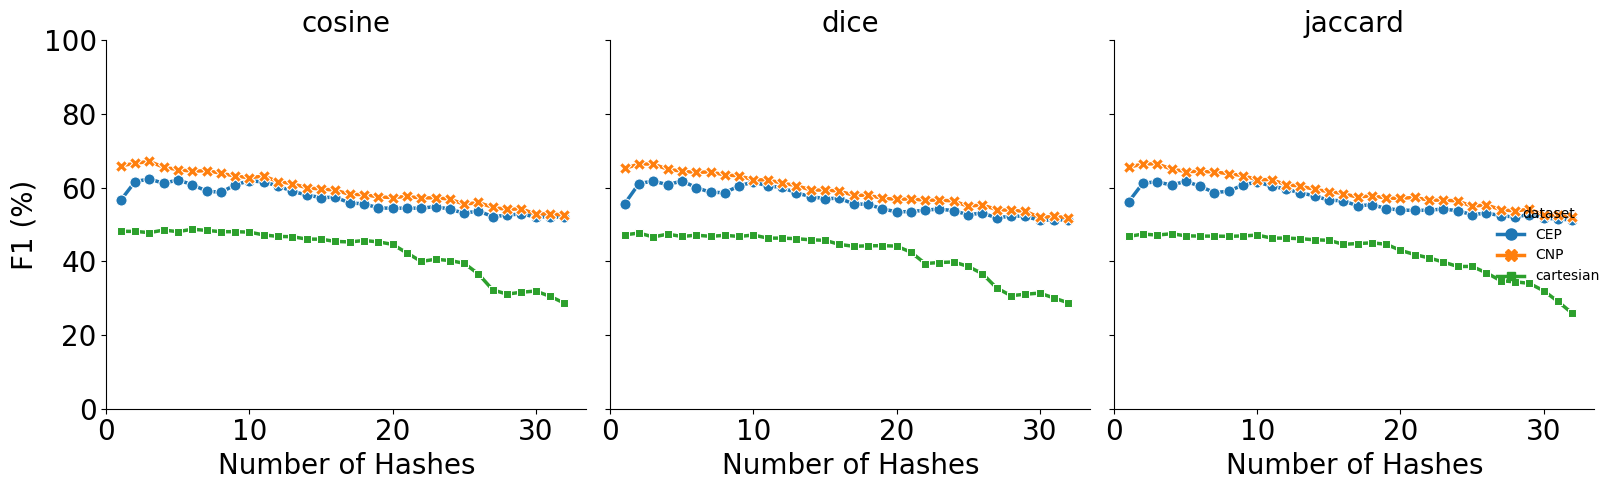

In [6]:
g = sns.relplot(
    data=max_f1,
    x="num_hashes",
    y="F1 %",
    hue="dataset",
    style="dataset",
    markers=True,
    dashes=False,      # solid lines but different markers
    col="similarity",
    kind="line",
    linewidth=2.5,
    markersize=8
)

for ax in g.axes.flat:
    ax.tick_params(axis='both', labelsize=20)
    
g.set_axis_labels("Number of Hashes", "F1 (%)", fontsize=20)
g.set(xlim=(0, None), ylim=(0, 100))
g.set_titles("{col_name}", size=20)

plt.tight_layout()
plt.show()

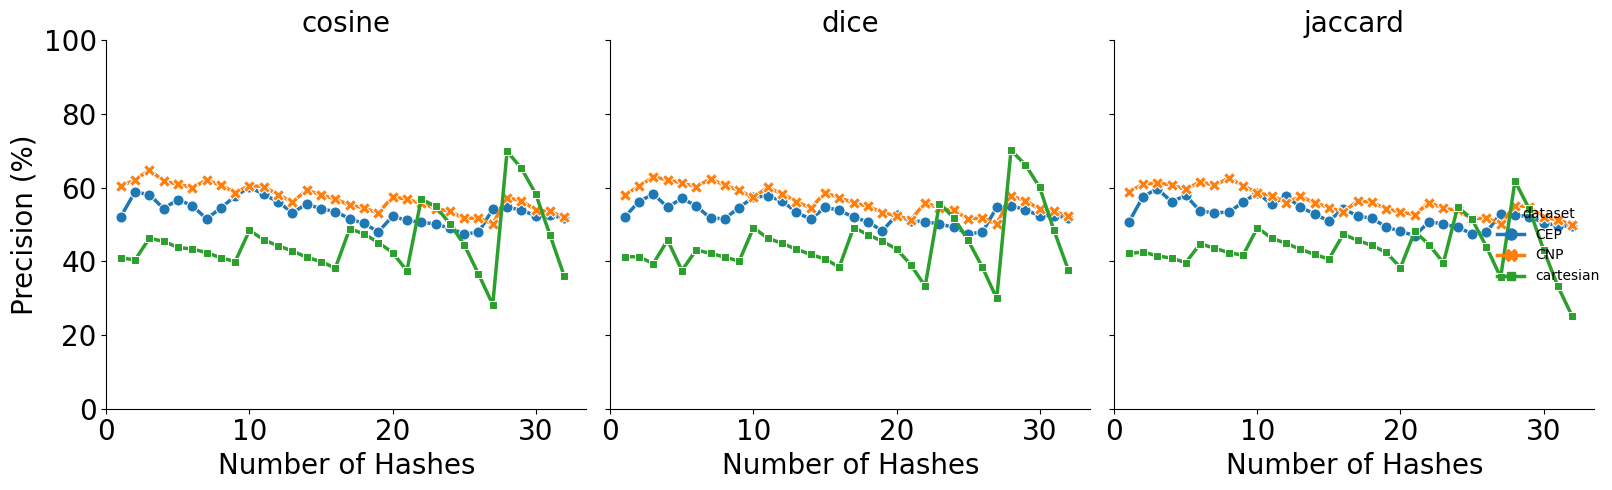

In [7]:
g = sns.relplot(
    data=max_f1,
    x="num_hashes",
    y="Precision %",
    hue="dataset",
    style="dataset",
    markers=True,
    dashes=False,      # solid lines but different markers
    col="similarity",
    kind="line",
    linewidth=2.5,
    markersize=8
)

for ax in g.axes.flat:
    ax.tick_params(axis='both', labelsize=20)
    
g.set_axis_labels("Number of Hashes", "Precision (%)", fontsize=20)
g.set(xlim=(0, None), ylim=(0, 100))
g.set_titles("{col_name}", size=20)

plt.tight_layout()
plt.show()

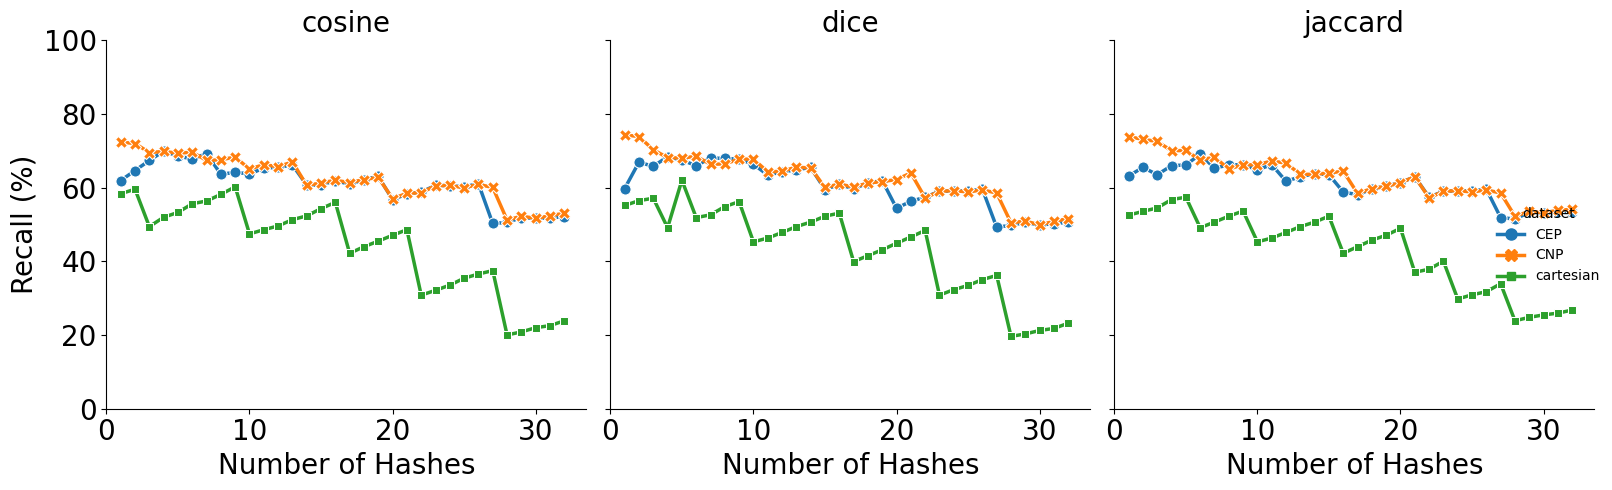

In [8]:
g = sns.relplot(
    data=max_f1,
    x="num_hashes",
    y="Recall %",
    hue="dataset",
    style="dataset",
    markers=True,
    dashes=False,      # solid lines but different markers
    col="similarity",
    kind="line",
    linewidth=2.5,
    markersize=8
)

for ax in g.axes.flat:
    ax.tick_params(axis='both', labelsize=20)
    
g.set_axis_labels("Number of Hashes", "Recall (%)", fontsize=20)
g.set(xlim=(0, None), ylim=(0, 100))
g.set_titles("{col_name}", size=20)

plt.tight_layout()
plt.show()

In [9]:
result['attributes'].value_counts()

[name]    9120
Name: attributes, dtype: int64

In [10]:
result['offset'].value_counts()

0    9120
Name: offset, dtype: int64

In [11]:
result['hashing_type'].value_counts()

salted_qgrams    9120
Name: hashing_type, dtype: int64

In [12]:
result['qgrams'].value_counts()

4    9120
Name: qgrams, dtype: int64

In [13]:
result['size'].value_counts()

1024    9120
Name: size, dtype: int64

In [14]:
result['num_hashes'].value_counts()

1     285
2     285
31    285
30    285
29    285
28    285
27    285
26    285
25    285
24    285
23    285
22    285
21    285
20    285
19    285
18    285
17    285
16    285
15    285
14    285
13    285
12    285
11    285
10    285
9     285
8     285
7     285
6     285
5     285
4     285
3     285
32    285
Name: num_hashes, dtype: int64